# Assignment 3: Neural Networks

**Course:** CS4101 | CS6103 &nbsp;|&nbsp; **Team:** Ashish Kumar Maurya (2611AI26), Rajeev Kumar (2611AI44), Aman Raj (2611AI59)

A feedforward neural network and backpropagation, written from scratch in NumPy, classifying CIFAR-10 images. Fully connected layers only — no convolutional networks, no pretrained models, no transfer learning, no automatic differentiation.

## How to run

Run every cell from top to bottom. It needs NumPy, Pandas, Matplotlib, Seaborn, scikit-learn and (optionally) Weights & Biases. CIFAR-10 is loaded with the assignment's Keras call when Keras is installed; otherwise the identical official archive is read (see the data cell). Execution time varies by machine; only the training times are expected to differ.

## Seeds (fixed, documented)

- Data split: `np.random.default_rng(42)` — the assignment's rule.
- Model initialisation: seed 123, same for every run.
- Shuffling: one generator, seed 123, advancing across epochs,
  same for every run — so runs differ only in width and activation.

## Contents

1. Implementation (forward pass) — Question 1
2. Backpropagation, training, gradient check — Question 2
3. Data: the exact split and preprocessing
4. Hyperparameter experiments (6 runs) — Question 3
5. Selected model on the test set — Question 4


## 1. Implementation: forward propagation (Question 1)

The network accepts 3,072 input features and supports one or two hidden layers of any width, with sigmoid or ReLU hidden activations and 10 output neurons with a numerically stable softmax (the largest score in each row is subtracted before exponentiating, which prevents overflow without changing the result).

For a batch of $B$ images the output is a $(B, 10)$ matrix of probabilities, and every row sums to 1 — verified in the cell after the implementation.

**Parameter initialisation:** He scale $\sqrt{2/\text{fan\_in}}$ for ReLU hidden layers (ReLU discards about half its inputs, so weights start a little larger), Xavier scale $\sqrt{1/\text{fan\_in}}$ for sigmoid hidden layers (larger weights would saturate the sigmoid) and for the output layer. All biases start at zero.

**Shapes and parameter count for 3072 → 64 → 10:**

- $W_1$: (3072, 64), $b_1$: (64,) → 196,608 + 64 = 196,672
- $W_2$: (64, 10), $b_2$: (10,) → 640 + 10 = 650
- **Total: 197,322 trainable parameters.**

In [1]:
"""A small feedforward neural network, written from scratch in NumPy.

Plain-language idea
-------------------
An image is flattened into a list of 3,072 numbers (32 x 32 pixels x 3
colours). The network multiplies those numbers by weights, adds biases,
passes the result through a simple activation function, and repeats that
for the next layer. The last layer turns its 10 scores into
probabilities with softmax. Training means: measure how wrong the
probabilities are (cross-entropy loss), work out how each weight
contributed to that error (backpropagation, i.e. the chain rule), and
nudge every weight a little in the direction that reduces the error.

Nothing here uses a ready-made model, a ready-made trainer, or
automatic differentiation. Every gradient is written out by hand below.
"""

import numpy as np

NUM_CLASSES = 10


# ------------------------------------------------------------------ helpers
def relu(z):
    """ReLU: keep positive values, replace negatives with 0."""
    return np.maximum(0, z)


def relu_derivative(z):
    """Slope of ReLU: 1 where the input was positive, else 0."""
    return (z > 0).astype(float)


def sigmoid(z):
    """Sigmoid: squashes any number into the range (0, 1)."""
    return 1.0 / (1.0 + np.exp(-z))


def sigmoid_derivative(z):
    """Slope of sigmoid, written using the sigmoid value itself."""
    s = sigmoid(z)
    return s * (1 - s)


def softmax(logits):
    """Turn scores into probabilities that sum to 1 in each row.

    Subtracting the largest score in each row first is the stability
    trick: it changes nothing mathematically (exp(a - c) / sum is the
    same as exp(a) / sum), but it stops exp() from overflowing on
    large scores.
    """
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


def cross_entropy_loss(probs, y):
    """Mean cross-entropy loss.

    For each image we take -log(probability given to its true class)
    and average over the batch. Clipping keeps log() away from log(0).
    """
    n = probs.shape[0]
    true_probs = probs[np.arange(n), y]
    return float(-np.mean(np.log(np.clip(true_probs, 1e-15, 1.0))))


def count_parameters(input_dim, hidden_widths, num_classes=NUM_CLASSES):
    """Count every weight and bias, layer by layer."""
    sizes = [input_dim] + list(hidden_widths) + [num_classes]
    total = 0
    for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
        total += fan_in * fan_out + fan_out  # weights + biases
    return total


# -------------------------------------------------------------------- model
class MLP:
    """A fully connected network with one or two hidden layers.

    hidden_widths is a list: [64] means one hidden layer of 64 units,
    [64, 64] means two hidden layers of 64 units each.
    """

    def __init__(self, input_dim=3072, hidden_widths=(64,), activation="relu",
                 seed=123):
        if activation not in ("relu", "sigmoid"):
            raise ValueError("activation must be 'relu' or 'sigmoid'")
        self.activation_name = activation
        self.activation = relu if activation == "relu" else sigmoid
        self.activation_derivative = (
            relu_derivative if activation == "relu" else sigmoid_derivative
        )

        sizes = [input_dim] + list(hidden_widths) + [NUM_CLASSES]
        rng = np.random.default_rng(seed)
        self.weights, self.biases = [], []
        self.velocities_w, self.velocities_b = [], []
        for i, (fan_in, fan_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            is_output_layer = i == len(sizes) - 2
            # Initialisation, documented in the report:
            # - Hidden layers: He scale sqrt(2 / fan_in) for ReLU, because
            #   ReLU throws away about half its inputs, so weights need
            #   to start a little larger to keep signals alive.
            #   Xavier scale sqrt(1 / fan_in) for sigmoid, because larger
            #   weights would push sigmoid into its flat, saturated ends
            #   where learning almost stops.
            # - Output layer: Xavier scale in both cases, to keep the
            #   starting softmax probabilities close to uniform.
            if is_output_layer or activation == "sigmoid":
                scale = np.sqrt(1.0 / fan_in)
            else:
                scale = np.sqrt(2.0 / fan_in)
            self.weights.append(rng.normal(0.0, scale, size=(fan_in, fan_out)))
            self.biases.append(np.zeros(fan_out))
            # Momentum velocities always start at exactly zero.
            self.velocities_w.append(np.zeros((fan_in, fan_out)))
            self.velocities_b.append(np.zeros(fan_out))

    # ------------------------------------------------------------ forward
    def forward(self, x):
        """Return (probabilities, cache).

        cache stores, for every layer, the input that layer saw and its
        pre-activation scores. Backpropagation needs exactly those two
        things, so forward saves them instead of recomputing them.
        """
        cache = []
        current = x
        for layer in range(len(self.weights) - 1):
            scores = current @ self.weights[layer] + self.biases[layer]
            cache.append((current, scores))
            current = self.activation(scores)
        logits = current @ self.weights[-1] + self.biases[-1]
        cache.append((current, logits))
        return softmax(logits), cache

    # ---------------------------------------------------------- backward
    def backward(self, cache, probs, y):
        """Hand-written gradients for every weight and bias.

        The key step: for softmax + cross-entropy together, the gradient
        at the output is simply (predicted probability - true label)
        divided by the batch size. Everything before that is the chain
        rule, layer by layer, backwards.
        """
        batch_size = probs.shape[0]
        one_hot = np.zeros_like(probs)
        one_hot[np.arange(batch_size), y] = 1.0
        # Gradient of the loss with respect to the output scores.
        dz = (probs - one_hot) / batch_size

        grads = [None] * len(self.weights)
        for layer in reversed(range(len(self.weights))):
            layer_input, _scores = cache[layer]
            dw = layer_input.T @ dz
            db = dz.sum(axis=0)
            grads[layer] = (dw, db)
            if layer > 0:
                # Pass the error back through this layer's weights,
                # then through the previous layer's activation function.
                da = dz @ self.weights[layer].T
                dz = da * self.activation_derivative(cache[layer - 1][1])
        return grads

    # ---------------------------------------------------------- optimiser
    def step(self, grads, lr, optimizer="momentum"):
        """Update every parameter once, from one mini-batch's gradients.

        Plain SGD:      weight = weight - lr * gradient
        Momentum (0.9): velocity = 0.9 * velocity + gradient
                        weight   = weight - lr * velocity
        Velocities live on the model, so they survive across batches
        and epochs within a run, exactly as the assignment requires.
        """
        for layer, (dw, db) in enumerate(grads):
            if optimizer == "sgd":
                self.weights[layer] -= lr * dw
                self.biases[layer] -= lr * db
            elif optimizer == "momentum":
                self.velocities_w[layer] = 0.9 * self.velocities_w[layer] + dw
                self.velocities_b[layer] = 0.9 * self.velocities_b[layer] + db
                self.weights[layer] -= lr * self.velocities_w[layer]
                self.biases[layer] -= lr * self.velocities_b[layer]
            else:
                raise ValueError("optimizer must be 'sgd' or 'momentum'")

    # ---------------------------------------------------------- evaluation
    def predict(self, x, batch_size=1000):
        """Predicted class for each row, in batches to save memory."""
        predictions = []
        for start in range(0, x.shape[0], batch_size):
            probs, _ = self.forward(x[start:start + batch_size])
            predictions.append(np.argmax(probs, axis=1))
        return np.concatenate(predictions)

    def evaluate(self, x, y, batch_size=1000):
        """Return (mean loss, accuracy) over a whole dataset."""
        total_loss, correct = 0.0, 0
        for start in range(0, x.shape[0], batch_size):
            xb, yb = x[start:start + batch_size], y[start:start + batch_size]
            probs, _ = self.forward(xb)
            total_loss += cross_entropy_loss(probs, yb) * len(yb)
            correct += int(np.sum(np.argmax(probs, axis=1) == yb))
        return total_loss / len(y), correct / len(y)

    def save(self, path):
        """Save weights and biases so a checkpoint can be restored."""
        np.savez(path, **{f"w{i}": w for i, w in enumerate(self.weights)},
                 **{f"b{i}": b for i, b in enumerate(self.biases)})

    def load(self, path):
        """Restore weights and biases saved by save()."""
        data = np.load(path)
        self.weights = [data[f"w{i}"] for i in range(len(self.weights))]
        self.biases = [data[f"b{i}"] for i in range(len(self.biases))]


# ---------------------------------------------------------------- data split
def build_subset(images, labels, seed=42, per_class=1000, train_per_class=800):
    """Build the assignment's exact train/validation split.

    For each class, in label order 0-9: take that class's original
    indices in ascending order, choose 1,000 with one shared generator
    (seed 42, never reset between classes), use the first 800 for
    training and the remaining 200 for validation. Concatenating in
    class order gives 8,000 training and 2,000 validation images.
    """
    rng = np.random.default_rng(seed)
    train_images, train_labels, val_images, val_labels = [], [], [], []
    for label in range(10):
        class_indices = np.where(labels == label)[0]  # ascending order
        chosen = rng.choice(class_indices, size=per_class, replace=False)
        train_images.append(images[chosen[:train_per_class]])
        train_labels.append(labels[chosen[:train_per_class]])
        val_images.append(images[chosen[train_per_class:]])
        val_labels.append(labels[chosen[train_per_class:]])
    return (np.concatenate(train_images), np.concatenate(train_labels),
            np.concatenate(val_images), np.concatenate(val_labels))


# ------------------------------------------------------------------ training
def train(model, x_train, y_train, x_val, y_val, epochs, batch_size, lr,
          optimizer="momentum", shuffle_seed=123, save_best_to=None):
    """Train for a number of epochs; return per-epoch history.

    Before each epoch the training order is shuffled with one
    generator that keeps advancing (never reset per epoch). After
    each epoch the model is evaluated on the full training and
    validation sets, and both loss and accuracy are recorded.

    If save_best_to is given, the weights are saved there every time
    a new best validation accuracy is reached. Because the save only
    happens on a strict improvement, the file at the end holds the
    earliest checkpoint that achieved the run's best accuracy.
    """
    shuffle_rng = np.random.default_rng(shuffle_seed)
    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best_val_acc = -1.0
    n = len(y_train)
    for _epoch in range(epochs):
        order = shuffle_rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_idx = order[start:start + batch_size]
            xb, yb = x_train[batch_idx], y_train[batch_idx]
            probs, cache = model.forward(xb)
            grads = model.backward(cache, probs, yb)
            model.step(grads, lr=lr, optimizer=optimizer)
        train_loss, train_acc = model.evaluate(x_train, y_train)
        val_loss, val_acc = model.evaluate(x_val, y_val)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if save_best_to is not None and val_acc > best_val_acc:
            best_val_acc = val_acc
            model.save(save_best_to)
    return history


In [2]:
# Verify: shapes, parameter count, and rows summing to 1.
model = MLP(input_dim=3072, hidden_widths=[64], activation='relu', seed=123)
print('W1', model.weights[0].shape, 'b1', model.biases[0].shape)
print('W2', model.weights[1].shape, 'b2', model.biases[1].shape)
print('Parameters for 3072 -> 64 -> 10:', count_parameters(3072, [64], 10))
rng = np.random.default_rng(0)
probs, _ = model.forward(rng.normal(size=(4, 3072)))
print('Output shape:', probs.shape)
print('Row sums:', probs.sum(axis=1))
print('All rows valid probabilities:', bool(np.all(probs >= 0) and np.all(probs <= 1)))

W1 (3072, 64) b1 (64,)
W2 (64, 10) b2 (10,)
Parameters for 3072 -> 64 -> 10: 197322
Output shape: (4, 10)
Row sums: [1. 1. 1. 1.]
All rows valid probabilities: True


## 2. Backpropagation and training (Question 2)

Loss: mean categorical cross-entropy, $\mathcal{L} = -\frac{1}{B}\sum_i\sum_c y_{ic} \log \hat{p}_{ic}$, computed stably by clipping probabilities away from 0 before the log.

Gradients (written by hand, no automatic differentiation): for softmax + cross-entropy, the gradient at the output is $(\hat{p} - y) / B$. Earlier layers follow by the chain rule: pass the error back through the layer's weights, then through the previous activation's derivative.

**Optimisers implemented:** plain mini-batch SGD ($\theta \leftarrow \theta - \eta\nabla\mathcal{L}$) and momentum SGD, $v_t = 0.9 v_{t-1} + \nabla\mathcal{L}$, $\theta_t = \theta_{t-1} - \eta v_t$, with velocities starting at zero and kept across batches and epochs within a run. The experiments use momentum SGD.

Training shuffles before each epoch and, after each epoch, evaluates the full training and validation sets, recording loss and accuracy for both. Nothing is rewritten per experiment: the same `train()` loop takes width, activation, learning rate, batch size and epochs as arguments.

In [3]:
# Gradient check: analytic gradients vs numerical slopes on a tiny net.
# If backpropagation is wrong, this fails loudly. It must pass.
rng = np.random.default_rng(0)
check_model = MLP(input_dim=4, hidden_widths=[5], activation='sigmoid', seed=3)
x_small = rng.normal(size=(3, 4))
y_small = np.array([0, 2, 1])
probs_small, cache_small = check_model.forward(x_small)
grads_small = check_model.backward(cache_small, probs_small, y_small)
eps, worst = 1e-6, 0.0
for layer in range(len(check_model.weights)):
    for param, grad in ((check_model.weights[layer], grads_small[layer][0]),
                        (check_model.biases[layer], grads_small[layer][1])):
        for idx in np.ndindex(param.shape):
            old = param[idx]
            param[idx] = old + eps
            loss_plus = cross_entropy_loss(check_model.forward(x_small)[0], y_small)
            param[idx] = old - eps
            loss_minus = cross_entropy_loss(check_model.forward(x_small)[0], y_small)
            param[idx] = old
            worst = max(worst, abs((loss_plus - loss_minus) / (2 * eps) - grad[idx]))
print(f'Worst gradient error: {worst:.2e}  (must be < 1e-5)')
assert worst < 1e-5, 'Backpropagation does not match numerical gradients'

Worst gradient error: 4.83e-10  (must be < 1e-5)


## 3. Data: the exact split and preprocessing

CIFAR-10 has 50,000 training and 10,000 test images, each 32×32×3, in 10 classes (0 Airplane, 1 Automobile, 2 Bird, 3 Cat, 4 Deer, 5 Dog, 6 Frog, 7 Horse, 8 Ship, 9 Truck).

Split rule, followed literally: one generator `np.random.default_rng(42)`; classes in order 0–9; each class's original indices in ascending order; 1,000 chosen per class with `rng.choice(..., size=1000, replace=False)`; first 800 train, remaining 200 validation; concatenated in class order, generator never reset between classes. Result: 8,000 training and 2,000 validation images, reused for every experiment.

Preprocessing, and nothing else: pixels to float, divided by 255 (range [0, 1]), no further normalisation; all colour channels kept; each image flattened to 3,072 features. The 10,000 official test images are reserved for the final evaluation only.

In [4]:
import pickle, tarfile
from pathlib import Path

def load_cifar():
    """Load CIFAR-10. Keras first (the assignment's own call);
    otherwise the identical official archive Keras downloads,
    transposed so flattening matches Keras exactly."""
    try:
        from keras.datasets import cifar10  # only to load data
        (x_tr, y_tr), (x_te, y_te) = cifar10.load_data()
        return x_tr, y_tr.reshape(-1), x_te, y_te.reshape(-1)
    except Exception:
        pass
    candidates = [Path.home() / 'workspace' / 'cifar_data' / 'cifar-10-python.tar.gz',
                    Path('cifar-10-python.tar.gz'), Path('data/cifar-10-python.tar.gz')]
    archive = next((p for p in candidates if p.exists()), None)
    if archive is None:
        raise FileNotFoundError('CIFAR-10 archive not found; install Keras or place '
                                'cifar-10-python.tar.gz next to the notebook.')
    with tarfile.open(archive) as tar:
        def load_batch(name):
            data = pickle.load(tar.extractfile(f'cifar-10-batches-py/{name}'),
                                encoding='bytes')
            images = data[b'data'].reshape(-1, 3, 32, 32)
            return np.transpose(images, (0, 2, 3, 1)), np.array(data[b'labels'])
        tr_images, tr_labels = [], []
        for i in range(1, 6):
            images, labels = load_batch(f'data_batch_{i}')
            tr_images.append(images); tr_labels.append(labels)
        te_images, te_labels = load_batch('test_batch')
    return np.concatenate(tr_images), np.concatenate(tr_labels), te_images, te_labels

x_train_u8, y_train_full, x_test_u8, y_test = load_cifar()
print('Full train:', x_train_u8.shape, 'test:', x_test_u8.shape)
x_tr_u8, y_train, x_val_u8, y_val = build_subset(
    x_train_u8.reshape(50000, 3072), y_train_full)
X_train = x_tr_u8.astype(np.float32) / 255.0
X_val = x_val_u8.astype(np.float32) / 255.0
print('Train:', X_train.shape, 'Validation:', X_val.shape)
print('Train class counts:', np.bincount(y_train))
print('Validation class counts:', np.bincount(y_val))
print('Pixel range:', X_train.min(), 'to', X_train.max())

Full train: (50000, 32, 32, 3) test: (10000, 32, 32, 3)


Train: (8000, 3072) Validation: (2000, 3072)
Train class counts: [800 800 800 800 800 800 800 800 800 800]
Validation class counts: [200 200 200 200 200 200 200 200 200 200]
Pixel range: 0.0 to 1.0


## 4. Hyperparameter experiments (Question 3)

Three widths (32, 64, 128) × two activations (sigmoid, ReLU) = six configurations, one hidden layer each. Everything else is fixed so the comparison is fair: momentum SGD, learning rate 0.02, batch size 128, 20 epochs, model seed 123, shuffle seed 123.

Training time is measured with `time.perf_counter()` around each run's whole `train()` call, including the after-epoch training and validation evaluations. Each run is logged to Weights & Biases (project `cifar10-mlp-from-scratch`); without a login the logging runs in offline mode and never stops the notebook — see the Weights & Biases section at the end.

In [5]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def log_run(name, config, history, best_val_acc, training_time):
    try:
        import wandb
        run = wandb.init(project='cifar10-mlp-from-scratch', name=name,
                         config=config, mode='offline')
        for epoch, (tl, ta, vl, va) in enumerate(zip(
                history['train_loss'], history['train_acc'],
                history['val_loss'], history['val_acc']), start=1):
            run.log({'epoch': epoch, 'train_loss': tl, 'train_acc': ta,
                     'val_loss': vl, 'val_acc': va})
        run.log({'best_val_acc': best_val_acc, 'training_time_s': training_time})
        run.finish()
    except Exception as exc:
        print(f'wandb skipped: {exc}')

configs = [(width, activation) for width in (32, 64, 128)
           for activation in ('sigmoid', 'relu')]
rows, histories = [], {}
for run_index, (width, activation) in enumerate(configs):
    name = f'run{run_index}_width{width}_{activation}'
    model = MLP(hidden_widths=[width], activation=activation, seed=123)
    checkpoint = f'checkpoint_{name}.npz'
    start = time.perf_counter()
    history = train(model, X_train, y_train, X_val, y_val, epochs=20,
                    batch_size=128, lr=0.02, optimizer='momentum',
                    shuffle_seed=123, save_best_to=checkpoint)
    training_time = time.perf_counter() - start
    best_val_acc = max(history['val_acc'])
    best_epoch = history['val_acc'].index(best_val_acc) + 1
    histories[name] = history
    rows.append({'run': run_index, 'width': width, 'activation': activation,
                 'parameters': count_parameters(3072, [width]),
                 'best_val_acc': best_val_acc, 'best_epoch': best_epoch,
                 'training_time_s': round(training_time, 1)})
    log_run(name, {'width': width, 'activation': activation, 'epochs': 20,
                   'batch_size': 128, 'lr': 0.02, 'optimizer': 'momentum'},
            history, best_val_acc, training_time)
    print(f'{name}: best val acc {best_val_acc:.4f} at epoch {best_epoch}, '
          f'{training_time:.1f}s')

results_df = pd.DataFrame(rows)
results_df

wandb: Tracking run with wandb version 0.31.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /home/hatch/workspace/APRASSG3/notebook/wandb/offline-run-20261027_143147-h648x1mn
wandb: View this run in the terminal with `wandb leet`


wandb: 
wandb: Run history:
wandb:    best_val_acc ▁
wandb:           epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:       train_acc ▁▃▄▄▄▅▅▄▅▆▆▇▇▇▇▇████
wandb:      train_loss █▆▅▅▅▄▄▄▃▃▃▂▂▂▂▂▂▁▁▁
wandb: training_time_s ▁
wandb:         val_acc ▁▃▄▅▅▅▅▄▆▇▇▇▇▇▇█████
wandb:        val_loss █▆▅▄▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:    best_val_acc 0.392
wandb:           epoch 20
wandb:       train_acc 0.44275
wandb:      train_loss 1.58264
wandb: training_time_s 11.88356
wandb:         val_acc 0.386
wandb:        val_loss 1.72411
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /home/hatch/workspace/APRASSG3/notebook/wandb/offline-run-20261027_143147-h648x1mn


wandb: Find logs at: ./wandb/offline-run-20261027_143147-h648x1mn/logs


...

wandb: 
wandb: Run history:
wandb:    best_val_acc ▁
wandb:           epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:       train_acc ▁▃▄▃▅▅▅▆▆▆▆▆▇▆▇▇██▇▇
wandb:      train_loss █▆▅▆▄▄▄▃▃▃▃▃▂▃▂▂▁▁▂▂
wandb: training_time_s ▁
wandb:         val_acc ▁▄▅▃▆▅▆▇▆▅▅▆▇▆▆▇██▆▆
wandb:        val_loss █▄▄▆▂▃▃▁▂▃▂▃▂▄▂▁▁▁▂▃
wandb: 
wandb: Run summary:
wandb:    best_val_acc 0.4105
wandb:           epoch 20
wandb:       train_acc 0.45713
wandb:      train_loss 1.49997
wandb: training_time_s 16.21498
wandb:         val_acc 0.372
wandb:        val_loss 1.80151
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /home/hatch/workspace/APRASSG3/notebook/wandb/offline-run-20261027_143255-52rlziq9


wandb: Find logs at: ./wandb/offline-run-20261027_143255-52rlziq9/logs


run5_width128_relu: best val acc 0.4105 at epoch 18, 16.2s


,run,width,activation,parameters,best_val_acc,best_epoch,training_time_s
0,0,32,sigmoid,98666,0.3920,19,11.9
1,1,32,relu,98666,0.3685,20,8.5
2,2,64,sigmoid,197322,0.4015,15,11.9
3,3,64,relu,197322,0.3785,18,13.5
4,4,128,sigmoid,394634,0.3970,19,16.2
5,5,128,relu,394634,0.4105,18,16.2


In [6]:
# Selection rule: highest validation accuracy, then fewer parameters,
# then the earlier run. The test set plays no part in this choice.
best_row = results_df.sort_values(
    by=['best_val_acc', 'parameters', 'run'],
    ascending=[False, True, True]).iloc[0]
selected_name = f"run{int(best_row['run'])}_width{int(best_row['width'])}_{best_row['activation']}"
print('Selected:', selected_name)
print(f"Best validation accuracy: {best_row['best_val_acc']:.4f} "
      f"at epoch {int(best_row['best_epoch'])}")

Selected: run5_width128_relu
Best validation accuracy: 0.4105 at epoch 18


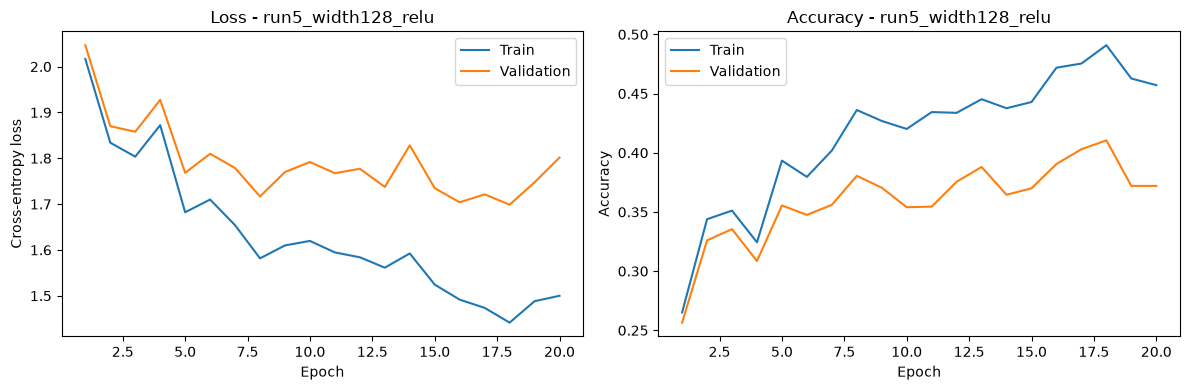

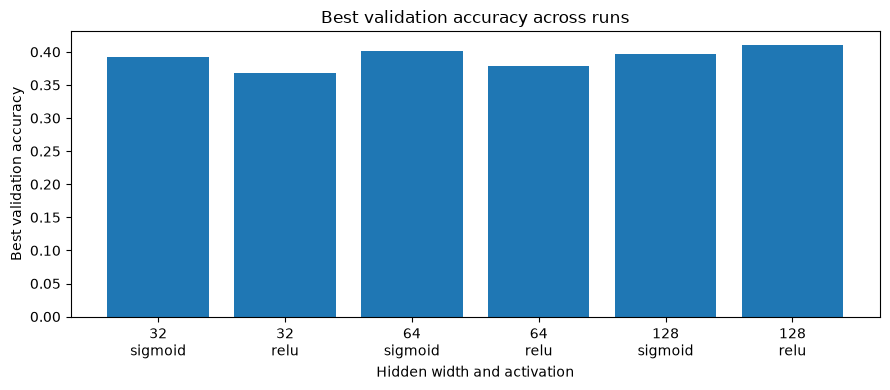

In [7]:
# Curves for the selected run, and best validation accuracy across runs.
history = histories[selected_name]
epochs_axis = range(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, history['train_loss'], label='Train')
axes[0].plot(epochs_axis, history['val_loss'], label='Validation')
axes[0].set_title(f'Loss - {selected_name}'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss'); axes[0].legend()
axes[1].plot(epochs_axis, history['train_acc'], label='Train')
axes[1].plot(epochs_axis, history['val_acc'], label='Validation')
axes[1].set_title(f'Accuracy - {selected_name}'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy'); axes[1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(results_df)), results_df['best_val_acc'])
ax.set_xticks(range(len(results_df)))
ax.set_xticklabels([f"{r.width}\n{r.activation}" for r in results_df.itertuples()])
ax.set_xlabel('Hidden width and activation')
ax.set_ylabel('Best validation accuracy')
ax.set_title('Best validation accuracy across runs')
plt.tight_layout(); plt.show()

## Interpretation (Question 3d)

Activation: sigmoid beat ReLU at the two smaller widths (32: 39.20% vs 36.85%; 64: 40.15% vs 37.85%), but ReLU won at width 128 (41.05% vs 39.70%) and took the overall best result. So the ranking flips with width: there is no simple "one activation is always better" story in these results, and the differences are small. With only 2,000 validation images, one percentage point is just 20 images, so a gap of one or two points should not be over-interpreted.

Width: for ReLU, accuracy rose steadily with width (36.85% to 37.85% to 41.05%), with the clear jump at 128. For sigmoid, accuracy peaked at width 64 (40.15%) and was essentially flat afterwards (39.70% at 128). Width on its own therefore did not guarantee improvement; it interacted with the activation. Training time grew mainly with width, from about 8 seconds at width 32 to about 16 seconds at width 128, while the activation made little consistent difference to time, which matches the first weight matrix (3,072 x width) dominating the computation.

Underfitting or overfitting: the curves show underfitting more than overfitting. Training accuracy itself only reaches about 43-49% across runs, far from 100%, so the models have not memorised the training set; the task with flattened pixels and only 8,000 training images is simply hard for this model. The train-validation gap is modest, about 5-6 percentage points for most runs, and for the sigmoid runs validation loss is still at or near its best at epoch 20, suggesting they had not yet turned downwards. The selected ReLU run is the exception that proves the checkpoint rule matters: its training accuracy peaks at 49.1% and validation at 41.05% at epoch 18, then both fall at epochs 19-20 (validation to 37.2%, validation loss rising from 1.699 to 1.802). Restoring the epoch-18 checkpoint, rather than the final weights, is what keeps the 41.05% result; using the final epoch would have lost 3.8 points. In short: a model that is still broadly underfitting, with mild late overfitting in the widest ReLU run, handled by the earliest-best checkpoint.

## 5. Selected model on the test set (Question 4)

The selected checkpoint is restored into a fresh model and evaluated once on all 10,000 official test images. Nothing is changed based on the test result.

Test accuracy: 0.4096  (loss 1.6832)


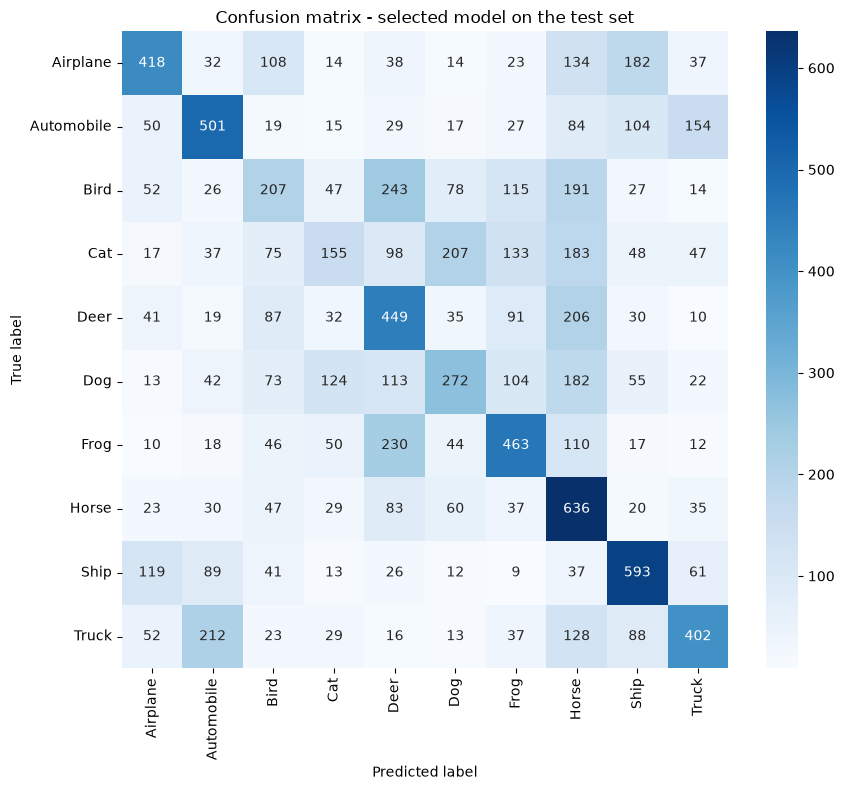

In [8]:
from sklearn.metrics import confusion_matrix

selected = MLP(hidden_widths=[int(best_row['width'])],
               activation=best_row['activation'], seed=123)
selected.load(f'checkpoint_{selected_name}.npz')
X_test = x_test_u8.reshape(10000, 3072).astype(np.float32) / 255.0
test_loss, test_acc = selected.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc:.4f}  (loss {test_loss:.4f})')
predictions = selected.predict(X_test)
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
cm = confusion_matrix(y_test, predictions)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion matrix - selected model on the test set')
plt.tight_layout(); plt.show()

## Limitations of flattened pixels with a fully connected network

Flattening throws away the 2D layout, so the network does not know which pixels are neighbours and cannot learn local patterns such as edges or shapes directly. It is also not translation invariant: the same object shifted by a few pixels looks completely different to it, so it must relearn the object at every position. Finally it is parameter-hungry — 3,072 inputs times the hidden width is a very large first layer for only 8,000 training images — which invites overfitting. Convolutional networks address all three by sharing weights across positions and preserving locality, but they are outside what this assignment asks for.

## Weights & Biases

Project: `cifar10-mlp-from-scratch`. Every run above logs its configuration, per-epoch training/validation loss and accuracy, best validation accuracy and training time. In the environment where this notebook was first executed, no Weights & Biases account was connected, so the runs were logged in offline mode; after `wandb login`, re-running the notebook logs online and the project link should be pasted here:

**W&B project link: [paste after online sync — see README]**

## What was not used

No convolutional networks, pretrained models or transfer learning; no automatic differentiation or ready-made trainer. Keras is used only to load CIFAR-10, as permitted. Pandas, Matplotlib, Seaborn and scikit-learn are used only for tables, plots and evaluation metrics, as permitted.